# Fase 2 · EXPLORE — Análisis exploratorio de datos

**Objetivo:** examinar las características y distribuciones del dataset para identificar patrones,
inconsistencias, desequilibrios y relaciones relevantes antes de modelar.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE))
sys.path.insert(0, str(BASE / "notebooks"))
import estilo as E  # noqa: E402
from vulnminer import caracteristicas as C  # noqa: E402
from vulnminer.catalogo import API2023, OWASP2025, nombre_categoria  # noqa: E402
from vulnminer.lexico import limpiar_codigo  # noqa: E402

E.aplicar()
df = pd.read_csv(BASE / "datos" / "dataset.csv", keep_default_na=False)
df["lineas"] = df.codigo.str.count("\n") + 1
df["caracteres"] = df.codigo.str.len()
vul = df[df.vulnerable == 1]
print(f"Registros: {len(df):,} | columnas: {df.shape[1]}")

Registros: 14,329 | columnas: 20


## 1. Registros y proporción de clases

vulnerable
No vulnerable    64.2 %
Vulnerable       35.8 %
Name: count, dtype: str


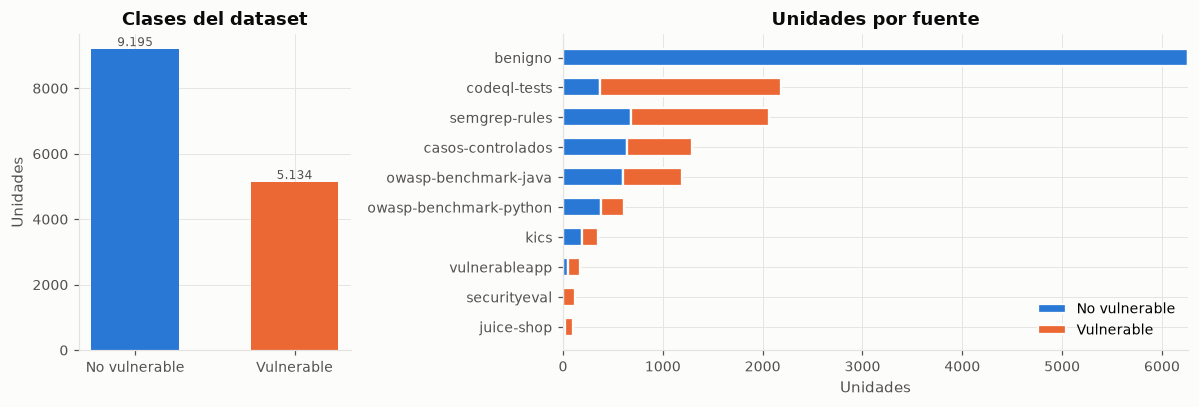

In [2]:
clases = df.vulnerable.map({0: "No vulnerable", 1: "Vulnerable"}).value_counts()
print((clases / len(df) * 100).round(1).astype(str) + " %")
por_fuente = pd.crosstab(df.fuente, df.vulnerable).rename(columns={0: "No vulnerable", 1: "Vulnerable"})
por_fuente = por_fuente.loc[por_fuente.sum(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2.3]})
b = axes[0].bar(clases.index, clases.values, color=[E.SEGURO if "No" in i else E.VULNERABLE for i in clases.index], width=0.55)
E.etiquetar_barras(axes[0], b)
axes[0].set_title("Clases del dataset")
axes[0].set_ylabel("Unidades")
izq = np.zeros(len(por_fuente))
for col, color in (("No vulnerable", E.SEGURO), ("Vulnerable", E.VULNERABLE)):
    axes[1].barh(por_fuente.index, por_fuente[col], left=izq, color=color, label=col, height=0.6, edgecolor=E.SUPERFICIE, linewidth=1.5)
    izq += por_fuente[col].values
axes[1].set_title("Unidades por fuente")
axes[1].set_xlabel("Unidades")
axes[1].legend(loc="lower right")
fig.tight_layout()
E.guardar(fig, "eda_clases_fuentes")
plt.show()

El dataset tiene más unidades no vulnerables que vulnerables (aprox. 2 a 1), que es lo realista: en un
proyecto la mayor parte del código no es vulnerable. El desbalance se trata en la fase Modify con pesos
de clase balanceados y con un umbral de decisión calibrado en validación.

## 2. Distribución por categoría OWASP

In [3]:
def conteo(col, orden):
    e = vul[col].str.split(";").explode()
    return e[e != ""].value_counts().reindex(orden, fill_value=0)

t10, api = conteo("owasp2025", list(OWASP2025)), conteo("api2023", list(API2023))
tabla = pd.DataFrame({"categoria": [nombre_categoria(c) for c in list(t10.index) + list(api.index)],
                      "unidades": list(t10.values) + list(api.values)}, index=list(t10.index) + list(api.index))
tabla

,categoria,unidades
A01:2025,Pérdida de control de acceso,1020
A02:2025,Configuración de seguridad incorrecta,381
A03:2025,Fallas en la cadena de suministro de software,61
A04:2025,Fallas criptográficas,725
A05:2025,Inyección,1910
A06:2025,Diseño inseguro,373
A07:2025,Fallas de autenticación,300
A08:2025,Fallas en la integridad del software o de los ...,266
A09:2025,"Fallas en el registro, alerta y monitoreo de s...",45
A10:2025,Manejo inadecuado de condiciones excepcionales,60


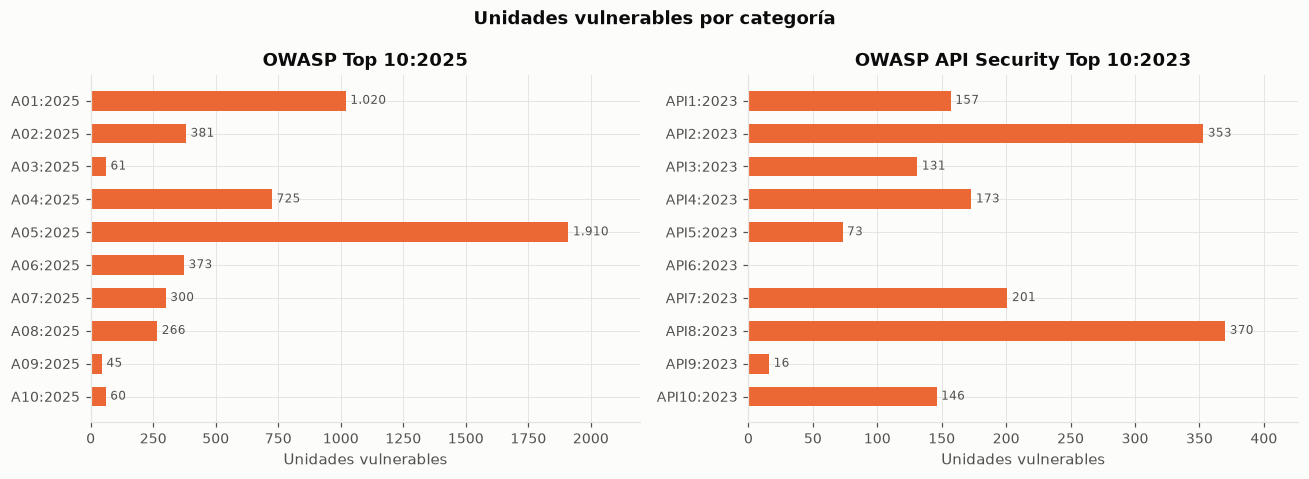

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, serie, titulo in ((axes[0], t10, "OWASP Top 10:2025"), (axes[1], api, "OWASP API Security Top 10:2023")):
    s = serie.iloc[::-1]
    barras = ax.barh(s.index, s.values, color=E.VULNERABLE, height=0.6)
    E.etiquetar_barras(ax, barras, horizontal=True)
    ax.set_title(titulo)
    ax.set_xlabel("Unidades vulnerables")
    ax.set_xlim(0, s.max() * 1.15 + 1)
fig.suptitle("Unidades vulnerables por categoría", fontweight="bold", color=E.TEXTO)
fig.tight_layout()
E.guardar(fig, "eda_categorias")
plt.show()

- **Mayor representación:** A05 Inyección, A01 Control de acceso y A04 Criptografía, porque son las más
  estudiadas por las herramientas de análisis estático.
- **Menor representación:** A03, A09 y A10 en el Top 10, y API5 y API9 en API Security. **API6** no tiene
  ejemplos: los flujos de negocio sensibles dependen de la lógica de cada aplicación y no de un patrón
  de código, por lo que se declarará *no evaluada*.
- Una misma unidad puede tener varias categorías (multietiqueta); por ejemplo, un BOLA es A01 y API1.

In [5]:
multi = (vul.owasp2025.str.count(";") + 1) + vul.api2023.apply(lambda s: len([x for x in s.split(";") if x]))
print("Etiquetas por unidad vulnerable:")
print(multi.value_counts().sort_index().rename("unidades").to_string())

Etiquetas por unidad vulnerable:
1    3606
2    1432
3      93
4       3


## 3. Lenguajes y tipos de archivo

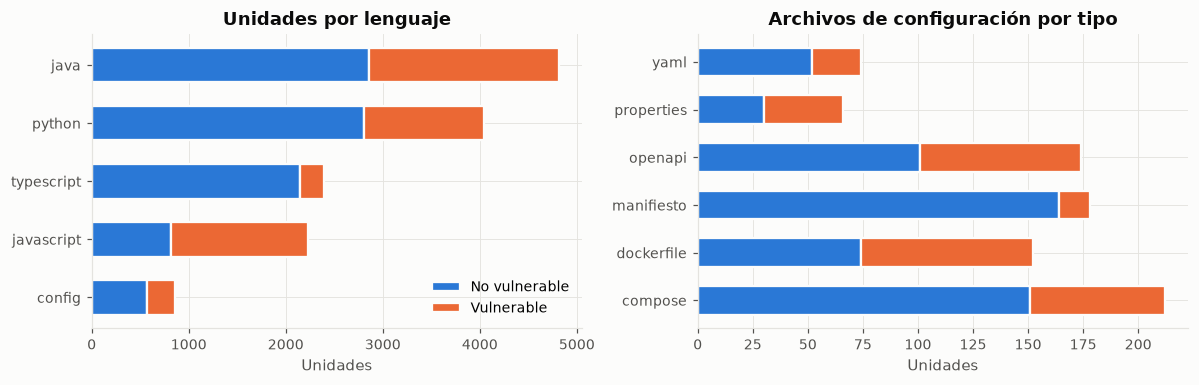

vulnerable,No vulnerable,Vulnerable,total
config,572,284,856
javascript,820,1409,2229
typescript,2144,245,2389
python,2805,1238,4043
java,2854,1958,4812
compose,151,61,212
dockerfile,74,78,152
manifiesto,164,14,178
openapi,101,73,174
properties,30,36,66


In [6]:
leng = pd.crosstab(df.lenguaje, df.vulnerable).rename(columns={0: "No vulnerable", 1: "Vulnerable"})
leng = leng.loc[leng.sum(axis=1).sort_values().index]
sub = pd.crosstab(df[df.lenguaje == "config"].subtipo, df[df.lenguaje == "config"].vulnerable).rename(
    columns={0: "No vulnerable", 1: "Vulnerable"})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, t, titulo in ((axes[0], leng, "Unidades por lenguaje"), (axes[1], sub, "Archivos de configuración por tipo")):
    izq = np.zeros(len(t))
    for col, color in (("No vulnerable", E.SEGURO), ("Vulnerable", E.VULNERABLE)):
        ax.barh(t.index, t[col], left=izq, color=color, label=col, height=0.6, edgecolor=E.SUPERFICIE, linewidth=1.5)
        izq += t[col].values
    ax.set_title(titulo)
    ax.set_xlabel("Unidades")
axes[0].legend(loc="lower right")
fig.tight_layout()
E.guardar(fig, "eda_lenguajes")
plt.show()
pd.concat([leng.assign(total=leng.sum(axis=1)), sub.assign(total=sub.sum(axis=1))])

## 4. Características de los fragmentos: longitud y estructura

In [7]:
desc = df.groupby(df.vulnerable.map({0: "No vulnerable", 1: "Vulnerable"}))[["lineas", "caracteres"]].describe().T.round(1)
desc

vulnerable        No vulnerable  Vulnerable
lineas     count         9195.0      5134.0
           mean            14.0        15.0
           std             13.2        13.4
           min              1.0         1.0
           25%              4.0         5.0
           50%              8.0         9.0
           75%             20.0        22.0
           max            156.0        60.0
caracteres count         9195.0      5134.0
           mean           567.6       692.4
           std            623.4       785.9
           min             22.0        28.0
           25%            155.0       198.0
           50%            307.0       355.0
           75%            755.5       926.0
           max          10043.0     11319.0

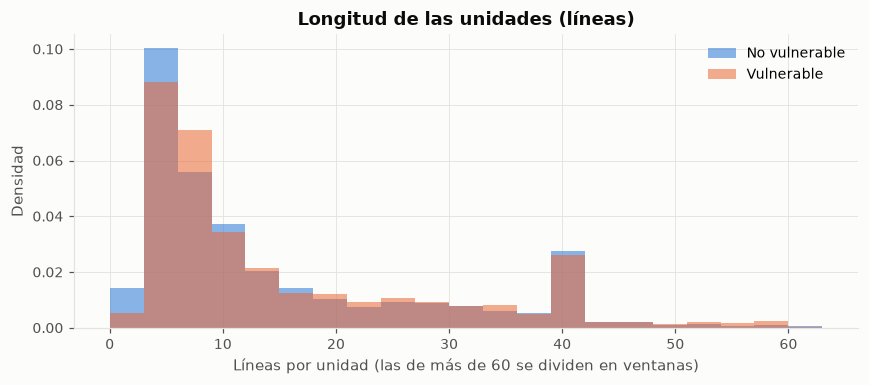

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 64, 3)
for v, color, nombre in ((0, E.SEGURO, "No vulnerable"), (1, E.VULNERABLE, "Vulnerable")):
    ax.hist(df[df.vulnerable == v].lineas.clip(upper=63), bins=bins, color=color, alpha=0.55, label=nombre, density=True)
ax.set_title("Longitud de las unidades (líneas)")
ax.set_xlabel("Líneas por unidad (las de más de 60 se dividen en ventanas)")
ax.set_ylabel("Densidad")
ax.legend()
fig.tight_layout()
E.guardar(fig, "eda_longitud")
plt.show()

Las unidades vulnerables son algo más cortas en promedio porque muchas provienen de pruebas de reglas,
que aíslan el patrón. Para que el modelo no use la longitud como atajo, la representación combina
TF-IDF normalizado (independiente de la longitud) con métricas de código en escala logarítmica.

## 5. Patrones frecuentes (indicadores de seguridad)

Prevalencia de los indicadores del análisis estático (porcentaje de unidades donde aparecen) en cada
clase. Los indicadores no deciden la clase: son variables que el modelo pondera.

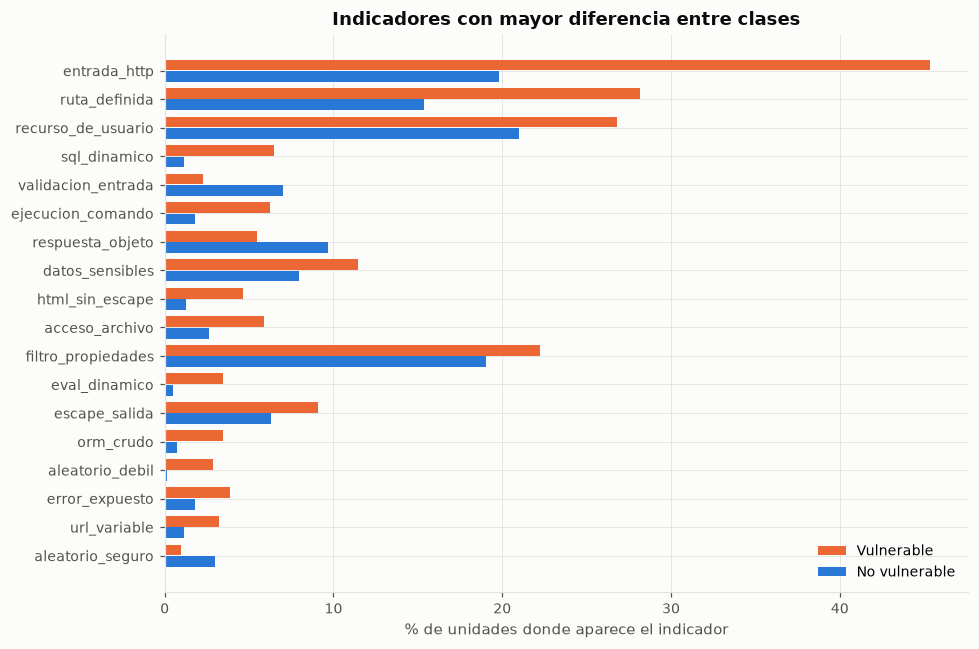

,No vulnerable,Vulnerable,diferencia
entrada_http,19.8,45.3,25.5
ruta_definida,15.4,28.2,12.8
recurso_de_usuario,21.0,26.8,5.8
sql_dinamico,1.1,6.5,5.4
ejecucion_comando,1.8,6.2,4.4
datos_sensibles,8.0,11.4,3.5
html_sin_escape,1.3,4.6,3.3
acceso_archivo,2.6,5.9,3.3
filtro_propiedades,19.1,22.3,3.2
eval_dinamico,0.5,3.4,3.0


In [9]:
muestra = df.sample(min(len(df), 6000), random_state=7)
from vulnminer.modelo import a_unidades  # noqa: E402

X = np.vstack([C.vector(u) for u in a_unidades(muestra)])
nombres = C.nombres_caracteristicas()
idx = [i for i, n in enumerate(nombres) if n in C.NOMBRES_INDICADORES]
prev = pd.DataFrame({
    "No vulnerable": (X[muestra.vulnerable.values == 0][:, idx] > 0).mean(axis=0) * 100,
    "Vulnerable": (X[muestra.vulnerable.values == 1][:, idx] > 0).mean(axis=0) * 100},
    index=[nombres[i] for i in idx])
prev["diferencia"] = prev["Vulnerable"] - prev["No vulnerable"]
top = prev.reindex(prev.diferencia.abs().sort_values(ascending=False).index).head(18).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(top))
ax.barh(y - 0.2, top["No vulnerable"], height=0.38, color=E.SEGURO, label="No vulnerable")
ax.barh(y + 0.2, top["Vulnerable"], height=0.38, color=E.VULNERABLE, label="Vulnerable")
ax.set_yticks(y, top.index)
ax.set_xlabel("% de unidades donde aparece el indicador")
ax.set_title("Indicadores con mayor diferencia entre clases")
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], loc="lower right")
fig.tight_layout()
E.guardar(fig, "eda_indicadores")
plt.show()
prev.sort_values("diferencia", ascending=False).round(1).head(25)

Las fuentes de entrada no confiable, las consultas SQL dinámicas, el hash débil y la ejecución de
comandos son mucho más frecuentes en el código vulnerable, mientras que la validación de entrada, el uso
de la identidad del usuario autenticado y las respuestas con propiedades seleccionadas lo son en el código
no vulnerable. Ningún indicador separa las clases por sí solo (todos aparecen en ambas), por lo que el
modelo debe aprender sus **combinaciones**: por ejemplo, una ruta con id y una búsqueda por id *sin*
verificación del propietario.

## 6. Calidad: duplicados, valores faltantes e inconsistencias

In [10]:
norm = df.codigo.map(lambda c: " ".join(limpiar_codigo(c).split()))
calidad = pd.Series({
    "registros": len(df),
    "códigos vacíos": int((df.codigo.str.strip() == "").sum()),
    "duplicados exactos (código normalizado)": int(norm.duplicated().sum()),
    "vulnerables sin CWE": int(((df.vulnerable == 1) & (df.cwe == "")).sum()),
    "vulnerables sin categoría Top 10": int(((df.vulnerable == 1) & (df.owasp2025 == "")).sum()),
    "no vulnerables con etiqueta": int(((df.vulnerable == 0) & ((df.cwe != "") | (df.owasp2025 != ""))).sum()),
    "grupos en más de una partición": int((df.groupby("proyecto").particion.nunique() > 1).sum()),
    "valores faltantes (cualquier columna obligatoria)": int(df[["id", "fuente", "archivo", "lenguaje", "codigo"]].eq("").sum().sum()),
})
calidad.to_frame("conteo")

,conteo
registros,14329
códigos vacíos,0
duplicados exactos (código normalizado),0
vulnerables sin CWE,0
vulnerables sin categoría Top 10,0
no vulnerables con etiqueta,0
grupos en más de una partición,0
valores faltantes (cualquier columna obligatoria),0


Las verificaciones dan cero en todos los casos porque la limpieza de la fase Sample ya eliminó los
duplicados (1 de cada 6 registros brutos) y las etiquetas contradictorias. Las pruebas automáticas
(`tests/test_dataset.py`) repiten estas comprobaciones cada vez que se reconstruye el dataset.

## 7. Desbalance entre clases y entre categorías

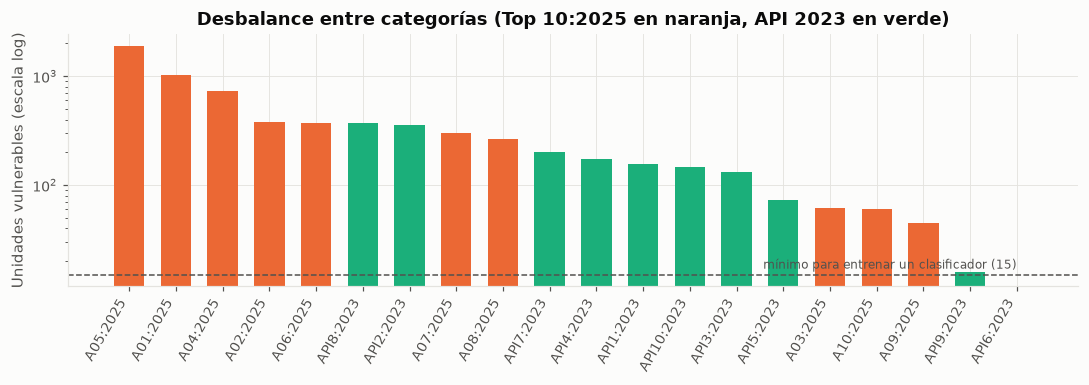

Relación entre la categoría más y la menos frecuente (con datos): 119 a 1


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.6))
serie = pd.concat([t10, api]).sort_values(ascending=False)
barras = ax.bar(serie.index, serie.values, color=[E.VULNERABLE if c.startswith("A") and not c.startswith("API") else E.AQUA for c in serie.index], width=0.65)
ax.axhline(15, color=E.TEXTO_2, linewidth=1, linestyle="--")
ax.annotate("mínimo para entrenar un clasificador (15)", (len(serie) - 1, 15), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=8, color=E.TEXTO_2)
ax.set_yscale("log")
ax.set_ylabel("Unidades vulnerables (escala log)")
ax.set_title("Desbalance entre categorías (Top 10:2025 en naranja, API 2023 en verde)")
plt.xticks(rotation=60, ha="right")
fig.tight_layout()
E.guardar(fig, "eda_desbalance")
plt.show()
print(f"Relación entre la categoría más y la menos frecuente (con datos): {serie[serie > 0].max() / serie[serie > 0].min():.0f} a 1")

## Conclusiones sobre la calidad y representatividad del dataset

1. **Tamaño suficiente y trazable:** más de 13 000 unidades de fuentes públicas identificadas por commit.
2. **Desbalance moderado entre clases** (≈ 2:1 a favor de no vulnerable), coherente con el código real.
3. **Desbalance fuerte entre categorías:** la inyección domina; A03, A09, A10, API5 y API9 tienen pocos
   ejemplos. Se aplicarán pesos balanceados, umbrales por categoría y un mínimo de 15 ejemplos para
   entrenar el clasificador de una categoría; las que no lo alcanzan se declaran *no evaluadas*.
4. **Diversidad de lenguajes y de archivos de configuración**, aunque la configuración (≈ 4 %) está menos
   representada que el código.
5. **Limitación:** gran parte de los ejemplos vulnerables proviene de pruebas de reglas, que son más cortas
   y aisladas que el código real; por eso la evaluación final se hace también sobre proyectos completos.